# 10 | Investigación de R² negativos

> **Cuaderno de reproducción (posterior).** Generado el 2026-10-23 como parte de la entrega docente. El repositorio original no contenía cuadernos versionados; estos reconstruyen los análisis a partir de los scripts y módulos existentes.

**Tipo de ejecución: ENTRENA ejemplo didáctico — regresión lineal de juguete (NO es un experimento del proyecto).**

In [1]:
import os
from pathlib import Path

def _raiz_repositorio() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'data' / 'raw' / 'interseccion_terrenos_zhg_r1_yacopi.csv').exists():
            return p
    raise FileNotFoundError('No se encontro la raiz del repositorio (busca data/raw)')

REPO = _raiz_repositorio()
print('Raiz del repositorio resuelta (carpeta):', REPO.name, '| data/raw encontrado')

Raiz del repositorio resuelta (carpeta): yacopi-project | data/raw encontrado


## Fórmula

`R² = 1 − Σ(y−ŷ)² / Σ(y−ȳ)²`

R² < 0 ⇒ el modelo tiene más error cuadrático que predecir la media del conjunto evaluado. No es un porcentaje de aciertos.

In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
rng = np.random.default_rng(7)
x_tr = np.linspace(0, 2, 60)
y_tr = (x_tr - 3)**2 + rng.normal(0, 0.2, size=60)
x_te = np.linspace(6, 10, 60)
y_te = (x_te - 3)**2 + rng.normal(0, 0.2, size=60)
m = LinearRegression().fit(x_tr.reshape(-1, 1), y_tr)
pred = m.predict(x_te.reshape(-1, 1))
print('R2 en prueba (entrenamiento y prueba separados) =', round(r2_score(y_te, pred), 3))
print('=> R2 negativo SIN error de programacion: la recta no extrapola la parabola')

R2 en prueba (entrenamiento y prueba separados) = -18.549
=> R2 negativo SIN error de programacion: la recta no extrapola la parabola


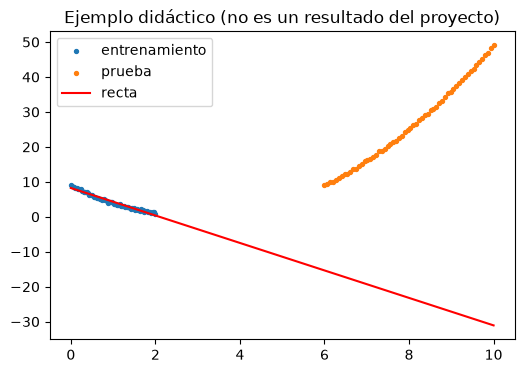

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.scatter(x_tr, y_tr, s=8, label='entrenamiento')
plt.scatter(x_te, y_te, s=8, label='prueba')
xs = np.linspace(0, 10, 50)
plt.plot(xs, m.predict(xs.reshape(-1,1)), 'r', label='recta')
plt.title('Ejemplo didáctico (no es un resultado del proyecto)')
plt.legend(); plt.show()

## Casos negativos reales de Atlas Vivo

Ver `AUDITORIA_R2_ATLAS_VIVO.md`. Resumen:
- Baseline ≈ 0 (por construcción).
- ZHG con zonas fuera: −1,70 (RF) y −2,18 (CatBoost).
- LOZO con varianza casi nula: −1e30 / NaN (R² indefinido).
- Escenario B: extremos por áreas mínimas dominan el error.
- v2 espacial A (CatBoost −0,075): bloques geográficos no vistos.